# Figures and tables

**Checking `results` directory**

In [1]:
!./5_check_results.py


1.1 z-threshold

✅ z_thresholds_best.json file found.

1.1 z-threshold

Task               f1       auc        acc       
-----------------------------------------------
healthy_vs_cancer  ✅        ✅          ✅         
cancer_vs_lr_hr    ✅        ✅          ✅         
MC                 ✅        ✅          ✅         

1.2 Mask-analysis

Task               Model    f1         auc        acc       
--------------------------------------------------------
healthy_vs_cancer  svm      ✅          ✅          ✅         
healthy_vs_cancer  rf       ✅          ✅          ✅         
healthy_vs_cancer  lr       ✅          ✅          ✅         
cancer_vs_lr_hr    svm      ✅          ✅          ✅         
cancer_vs_lr_hr    rf       ✅          ✅          ✅         
cancer_vs_lr_hr    lr       ✅          ✅          ✅         
MC                 svm      ✅          ✅          ✅         
MC                 rf       ✅          ✅          ✅         
MC                 lr       ✅          ✅          ✅  

**1.3 Frequency fold rankings**

In [2]:
# coloring IIVV paper
from toolbox.visualization import cmap_gradient, plot_freq_rank_heatmap

task='healthy_vs_cancer', metric='auc'


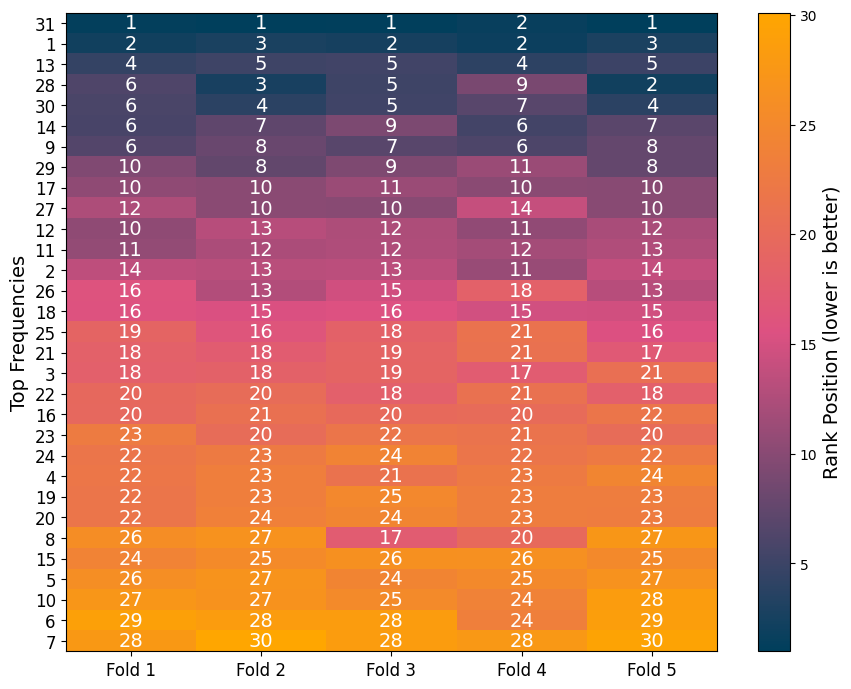

task='cancer_vs_lr_hr', metric='auc'


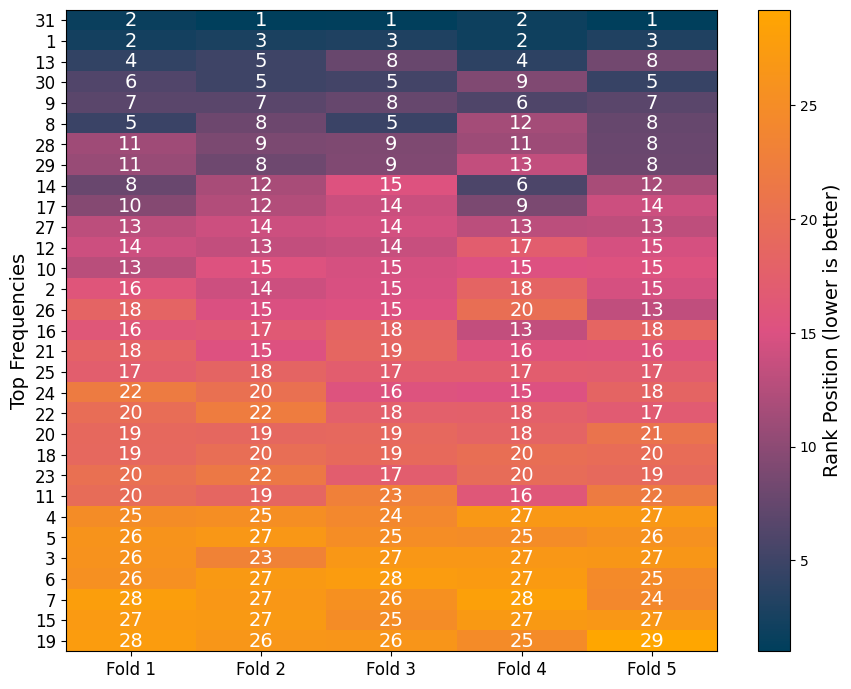

task='MC', metric='auc'


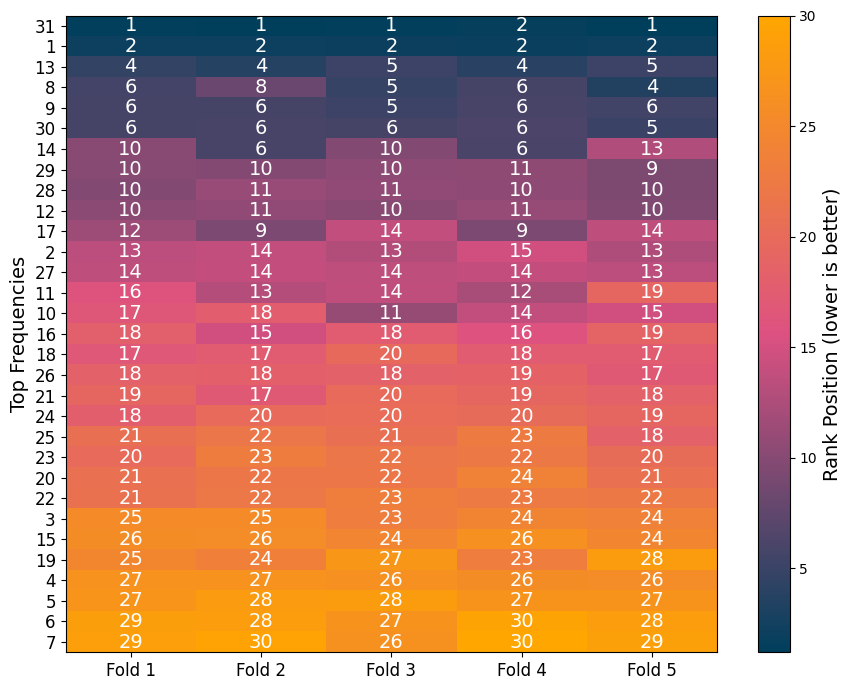

In [3]:
class_tasks = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]

metrics = [
    # "f1",
    "auc",
    # "acc",
]

for task in class_tasks:
    for metric in metrics:
        print(f"{task=}, {metric=}")
        plot_freq_rank_heatmap(task, metric, cmap=cmap_gradient)
# plot_freq_rank_heatmap("healthy_vs_cancer", "f1", cmap=cmap_gradient)

**1.3 Number of top frequencies**

In [4]:
from toolbox.visualization import plot_fold_means_with_error, plot_mean_across_folds

task='healthy_vs_cancer', metric='auc'


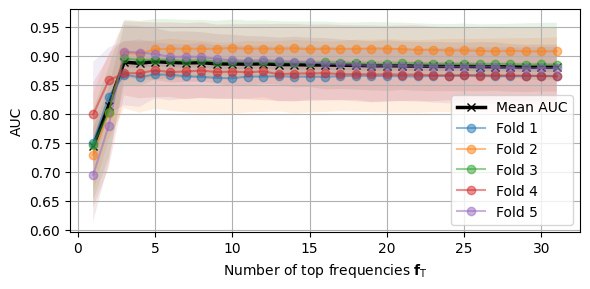

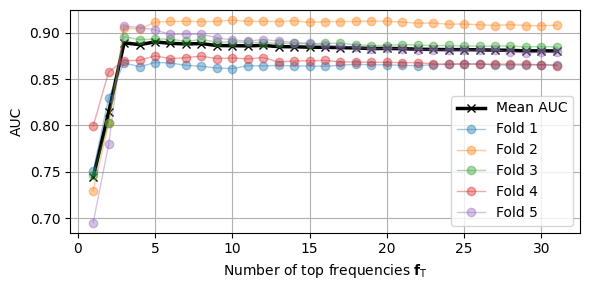

task='cancer_vs_lr_hr', metric='auc'


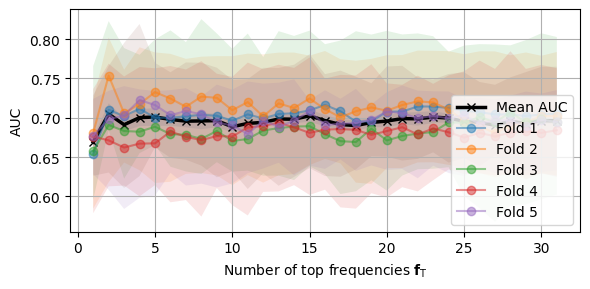

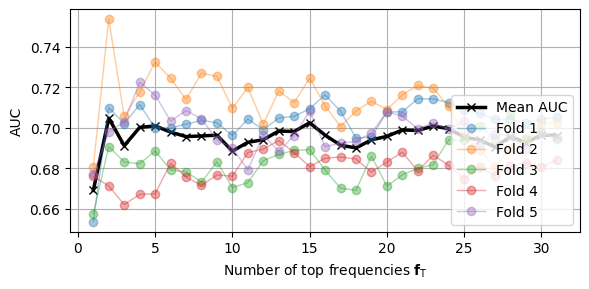

task='MC', metric='auc'


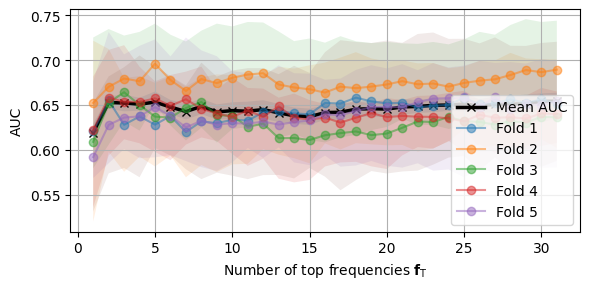

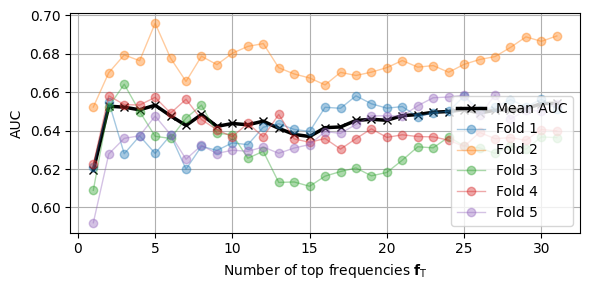

In [5]:
class_tasks = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]

metrics = [
    #"f1",
    "auc",
    #"acc",
]

for task in class_tasks:
   for metric in metrics:
       print(f"{task=}, {metric=}")
       plot_fold_means_with_error(task, metric, error="std")
       plot_mean_across_folds(task, metric)
# plot_mean_across_folds("MC", "f1")

## IIVV paper plots and tables

**Table VII**

In [6]:
import json
from pathlib import Path

import pandas as pd

RESULTS_DIR = Path("results")  # adjust if needed

TASKS = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]
TASK_LABELS = {
    "healthy_vs_cancer": "HvsC",
    "cancer_vs_lr_hr": "CvLRHR",
    "MC": "MC",
}

MODELS = ["svm", "rf", "lr"]
MODEL_LABELS = {"svm": "SVM", "rf": "RF", "lr": "LR"}


def load_baseline_summary(task: str) -> dict:
    fp = RESULTS_DIR / f"BASELINE_summary_{task}.json"
    if not fp.exists():
        raise FileNotFoundError(f"Missing: {fp.resolve()}")
    return json.loads(fp.read_text(encoding="utf-8"))


def get_metrics(summary: dict, model: str):
    m = summary["models"].get(model)
    if m is None:
        return None
    return {
        "f1": float(m.get("f1_mean", float("nan"))),
        "acc": float(m.get("accuracy_mean", float("nan"))),
        "auc": float(m.get("auc_mean", float("nan"))),
        "recall": float(m.get("recall_mean", float("nan"))),
        "precision": float(m.get("precision_mean", float("nan"))),
    }


summaries = {t: load_baseline_summary(t) for t in TASKS}

cols = []
for t in TASKS:
    cols += [(t, "f1"), (t, "acc"), (t, "auc"), (t, "recall"), (t, "precision")]

df = pd.DataFrame(
    index=[MODEL_LABELS[m] for m in MODELS], columns=pd.MultiIndex.from_tuples(cols)
)

for m in MODELS:
    for t in TASKS:
        met = get_metrics(summaries[t], m)
        if met is None:
            df.loc[MODEL_LABELS[m], (t, "f1")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "acc")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "auc")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "recall")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "precision")] = float("nan")
        else:
            df.loc[MODEL_LABELS[m], (t, "f1")] = met["f1"]
            df.loc[MODEL_LABELS[m], (t, "acc")] = met["acc"]
            df.loc[MODEL_LABELS[m], (t, "auc")] = met["auc"]
            df.loc[MODEL_LABELS[m], (t, "recall")] = met["recall"]
            df.loc[MODEL_LABELS[m], (t, "precision")] = met["precision"]

print(
    "Baseline results for Table VI. None of the models are tuned. Just the default Scikit-learn implemented models."
)
df = df.astype(float)

pd.options.display.float_format = "{:,.2f}".format
df

Baseline results for Table VI. None of the models are tuned. Just the default Scikit-learn implemented models.


healthy_vs_cancer                            cancer_vs_lr_hr            \
                   f1  acc  auc recall precision              f1  acc  auc   
SVM              0.81 0.82 0.88   0.81      0.81            0.59 0.59 0.79   
RF               0.81 0.81 0.88   0.83      0.80            0.60 0.60 0.81   
LR               0.77 0.78 0.82   0.79      0.77            0.58 0.58 0.74   

                       MC                             
    recall precision   f1  acc  auc recall precision  
SVM   0.59      0.59 0.59 0.59 0.79   0.59      0.59  
RF    0.60      0.60 0.59 0.59 0.81   0.59      0.59  
LR    0.58      0.58 0.53 0.53 0.74   0.53      0.53

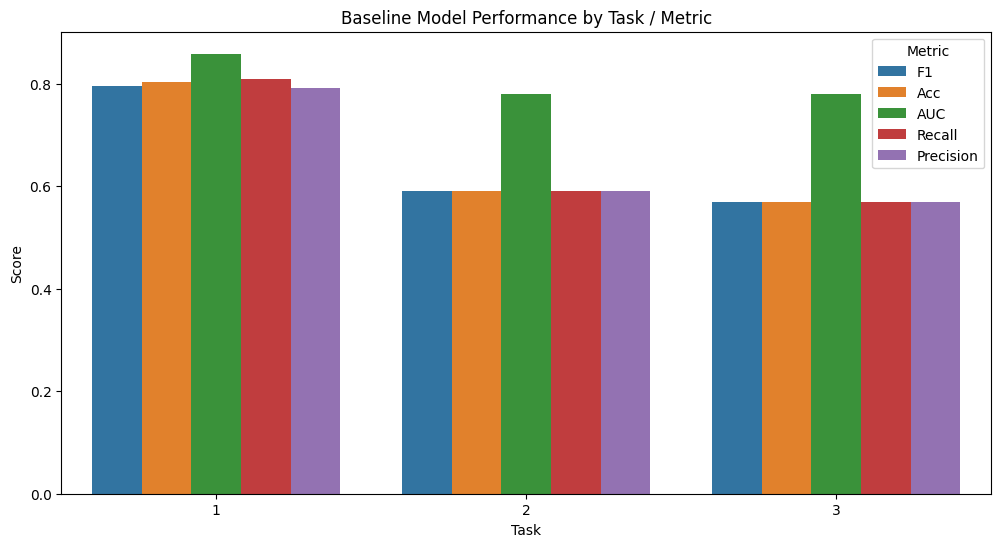

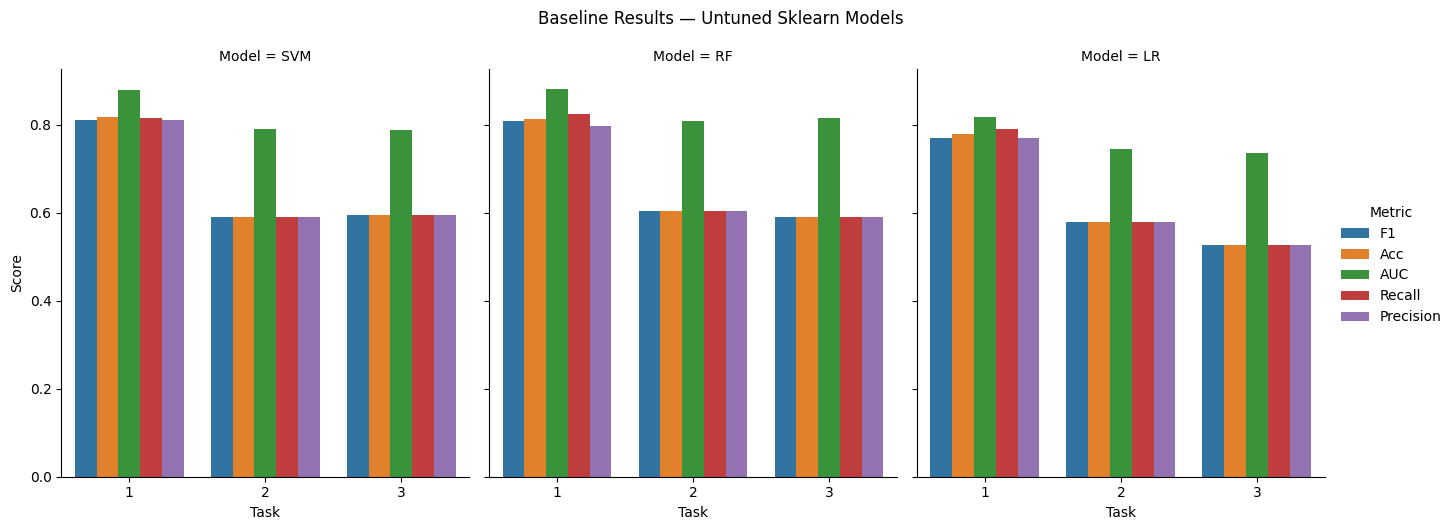

In [7]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RESULTS_DIR = Path("results")

TASKS = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]
TASK_LABELS = {
    "healthy_vs_cancer": "1",
    "cancer_vs_lr_hr": "2",
    "MC": "3",
}

MODELS = ["svm", "rf", "lr"]
MODEL_LABELS = {"svm": "SVM", "rf": "RF", "lr": "LR"}

METRICS = ["f1", "accuracy", "auc", "recall", "precision"]
METRIC_LABELS = {
    "f1": "F1",
    "accuracy": "Acc",
    "auc": "AUC",
    "recall": "Recall",
    "precision": "Precision",
}


def load_summary(task):
    fp = RESULTS_DIR / f"BASELINE_summary_{task}.json"
    return json.loads(fp.read_text(encoding="utf-8"))


rows = []

for task in TASKS:
    summary = load_summary(task)

    for model in MODELS:
        m = summary["models"].get(model)
        if m is None:
            continue

        values = {
            "f1": m.get("f1_mean"),
            "accuracy": m.get("accuracy_mean"),
            "auc": m.get("auc_mean"),
            "recall": m.get("recall_mean"),
            "precision": m.get("precision_mean"),
        }

        for metric, val in values.items():
            rows.append(
                {
                    "Task": TASK_LABELS[task],
                    "Model": MODEL_LABELS[model],
                    "Metric": METRIC_LABELS[metric],
                    "Score": float(val),
                }
            )

df = pd.DataFrame(rows)

# sort order
df["Task"] = pd.Categorical(df["Task"], [TASK_LABELS[t] for t in TASKS], ordered=True)
df["Model"] = pd.Categorical(
    df["Model"], [MODEL_LABELS[m] for m in MODELS], ordered=True
)
df["Metric"] = pd.Categorical(df["Metric"], list(METRIC_LABELS.values()), ordered=True)

# ---- Plot ----
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Task",
    y="Score",
    hue="Metric",
    dodge=True,
    errorbar=None,  # <-- keine Whisker
)

plt.title("Baseline Model Performance by Task / Metric")
plt.ylabel("Score")
plt.xlabel("Task")

# Modelle als Facet-Spalten
g = sns.catplot(
    data=df,
    kind="bar",
    x="Task",
    y="Score",
    hue="Metric",
    col="Model",
    errorbar=None,
    height=5,
    aspect=0.9,
)

g.fig.suptitle("Baseline Results — Untuned Sklearn Models", y=1.05)
g.set_axis_labels("Task", "Score")

plt.show()

**Final results of the tuned models**

In [8]:
from __future__ import annotations

from pathlib import Path
from typing import Dict, List

import pandas as pd

ROOT_DIR = Path("results")  # ggf. anpassen
WANTED_COLS = ["accuracy", "f1", "auc", "recall", "precision", "specificity"]


def discover_metrics_csvs(root: Path) -> Dict[str, Dict[str, Path]]:
    files: Dict[str, Dict[str, Path]] = {}
    for fp in root.rglob("METRICS_*_*.csv"):
        stem = fp.stem.replace("METRICS_", "")
        if "_" not in stem:
            continue
        task, metric = stem.rsplit("_", 1)
        files.setdefault(task, {})[metric] = fp
    return files


def build_table(files_by_task: Dict[str, Dict[str, Path]]) -> pd.DataFrame:
    rows: List[pd.DataFrame] = []

    for task, metrics_map in files_by_task.items():
        for metric, fp in metrics_map.items():
            df = pd.read_csv(fp)

            cols = [c for c in WANTED_COLS if c in df.columns]
            df = df[cols + (["model"] if "model" in df.columns else [])]

            df["tuned task"] = task
            df["tuning metric"] = metric

            if "model" in df.columns:
                df = df.set_index(["tuned task", "tuning metric", "model"])
            else:
                df = df.set_index(["tuned task", "tuning metric"])

            rows.append(df)

    if not rows:
        raise ValueError("No metric files found.")

    return pd.concat(rows).sort_index()


# ---- usage ----
files = discover_metrics_csvs(ROOT_DIR)
table = build_table(files)

pd.options.display.float_format = "{:,.4f}".format
table

accuracy     f1    auc  recall  \
tuned task            tuning metric model                                   
MC_lr                 acc           lr       0.5781 0.5781 0.7802  0.5781   
                      auc           lr       0.5898 0.5898 0.8103  0.5898   
                      f1            lr       0.5000 0.5000 0.7293  0.5000   
MC_rf                 acc           rf       0.5977 0.5977 0.7999  0.5977   
                      auc           rf       0.6016 0.6016 0.8254  0.6016   
                      f1            rf       0.6055 0.6055 0.7914  0.6055   
MC_svm                acc           svm      0.6055 0.6055 0.7880  0.6055   
                      auc           svm      0.5781 0.5781 0.8089  0.5781   
                      f1            svm      0.5469 0.5469 0.7307  0.5469   
cancer_vs_lr_hr_lr    acc           lr       0.6205 0.6205 0.8208  0.6205   
                      auc           lr       0.6446 0.6446 0.8204  0.6446   
                      f1            lr       0.6325 0.6325 0.8154  0.6325   
cancer_vs_lr_hr_rf    acc           rf       0.5602 0.5602 0.7808  0.5602   
                      auc           rf       0.5964 0.5964 0.8175  0.5964   
                      f1            rf       0.5783 0.5783 0.7822  0.5783   
cancer_vs_lr_hr_svm   acc           svm      0.5663 0.5663 0.6987  0.5663   
                      auc           svm      0.6446 0.6446 0.8229  0.6446   
                      f1            svm      0.5904 0.5904 0.8169  0.5904   
healthy_vs_cancer_lr  acc           lr       0.8011 0.7886 0.8315  0.7667   
                      auc           lr       0.8011 0.7886 0.9015  0.7667   
                      f1            lr       0.8065 0.7955 0.8749  0.7778   
healthy_vs_cancer_rf  acc           rf       0.8011 0.8000 0.8769  0.8222   
                      auc           rf       0.8065 0.7978 0.8911  0.7889   
                      f1            rf       0.8118 0.8087 0.8778  0.8222   
healthy_vs_cancer_svm acc           svm      0.8280 0.8261 0.8420  0.8444   
                      auc           svm      0.8172 0.8152 0.9006  0.8333   
                      f1            svm      0.8011 0.8122 0.8667  0.8889   

                                           precision  specificity  
tuned task            tuning metric model                          
MC_lr                 acc           lr        0.5781          NaN  
                      auc           lr        0.5898          NaN  
                      f1            lr        0.5000          NaN  
MC_rf                 acc           rf        0.5977          NaN  
                      auc           rf        0.6016          NaN  
                      f1            rf        0.6055          NaN  
MC_svm                acc           svm       0.6055          NaN  
                      auc           svm       0.5781          NaN  
                      f1            svm       0.5469          NaN  
cancer_vs_lr_hr_lr    acc           lr        0.6205          NaN  
                      auc           lr        0.6446          NaN  
                      f1            lr        0.6325          NaN  
cancer_vs_lr_hr_rf    acc           rf        0.5602          NaN  
                      auc           rf        0.5964          NaN  
                      f1            rf        0.5783          NaN  
cancer_vs_lr_hr_svm   acc           svm       0.5663          NaN  
                      auc           svm       0.6446          NaN  
                      f1            svm       0.5904          NaN  
healthy_vs_cancer_lr  acc           lr        0.8118       0.8333  
                      auc           lr        0.8118       0.8333  
                      f1            lr        0.8140       0.8333  
healthy_vs_cancer_rf  acc           rf        0.7789       0.7812  
                      auc           rf        0.8068       0.8229  
                      f1            rf        0.7957       0.8021  
healthy_vs_cancer_svm acc           svm  

In [9]:
import pandas as pd

tasks = [
    "healthy_vs_cancer",
    "cancer_vs_lr_hr",
    "MC",
]

metrics = ["auc"]  # ["acc", "auc", "f1"]

for task in tasks:
    for metric in metrics:
        filename = f"results/GPU_tuning_BEST_OVERALL_{task}_{metric}.csv"

        try:
            print("=" * 60)
            print(f"Task   : {task}")
            print(f"Metric : {metric}")
            print("=" * 60)

            df = pd.read_csv(filename)

            # Nur gewünschte Spalten anzeigen
            cols = ["model", "fsel", "msel", "score_mean", "n_params"]
            df_filtered = df[cols]

            print(df_filtered)
            print("\n\n")

        except FileNotFoundError:
            print(f"{filename} not found.\n")

Task   : healthy_vs_cancer
Metric : auc
  model   fsel       msel  score_mean  n_params
0   svm  Top 8  Skip1 far      0.9083      1792
1    lr  Top 8  Skip1 far      0.9080      1792
2    rf  Top 5   Adj. far      0.9052      3300



Task   : cancer_vs_lr_hr
Metric : auc
  model    fsel         msel  score_mean  n_params
0   svm  Top 15    Skip1 far      0.7955      3360
1    lr  Top 15    Skip1 far      0.7916      3360
2    rf  Top 15  Opp. medium      0.7770      3960



Task   : MC
Metric : auc
  model   fsel         msel  score_mean  n_params
0    rf  Top 3  Opp. medium      0.7791       792
1    lr  Top 3    Skip1 far      0.7679       672
2   svm  Top 3    Skip1 far      0.7603       672





In [10]:
import pandas as pd

tasks = [
    "healthy_vs_cancer",
    "cancer_vs_lr_hr",
    "MC",
]

metrics = ["auc"]  # ["acc", "auc", "f1"]

for task in tasks:
    for metric in metrics:
        filename = f"results/GPU_tuning_BEST_OVERALL_{task}_{metric}.csv"

        try:
            print("=" * 60)
            print(f"Task   : {task}")
            print(f"Metric : {metric}")
            print("=" * 60)

            df = pd.read_csv(filename)

            cols = ["model","score_mean", "params_json"]
            df_filtered = df[cols]

            print(df_filtered)
            print("\n\n")

        except FileNotFoundError:
            print(f"{filename} not found.\n")

Task   : healthy_vs_cancer
Metric : auc
  model  score_mean                                        params_json
0   svm      0.9083  {"C": 0.001, "degree": 3, "gamma": 0.01, "kern...
1    lr      0.9080                      {"C": 0.001, "max_iter": 200}
2    rf      0.9052  {"max_depth": 16, "max_features": 0.3, "n_esti...



Task   : cancer_vs_lr_hr
Metric : auc
  model  score_mean                                        params_json
0   svm      0.7955                   {"C": 0.001, "kernel": "linear"}
1    lr      0.7916                      {"C": 0.001, "max_iter": 500}
2    rf      0.7770  {"max_depth": 8, "max_features": 0.7, "n_estim...



Task   : MC
Metric : auc
  model  score_mean                                        params_json
0    rf      0.7791  {"max_depth": 8, "max_features": 0.7, "n_estim...
1    lr      0.7679                      {"C": 0.01, "max_iter": 2000}
2   svm      0.7603                    {"C": 0.01, "kernel": "linear"}





In [11]:
df = pd.read_csv(f"results/FinalResults.csv")
df

,Task,Model,Tuning metric,Freq,IIVV mask,N_params,accuracy,F1,Auc,Recall,Precision
0,MC,rf,f1,Top 5,Opp. close,1320,0.6055,0.6055,0.7914,0.6055,0.6055
1,MC,lr,f1,Top 3,Skip1 close,1080,0.5000,0.5000,0.7293,0.5000,0.5000
2,MC,svm,f1,Top 5,Opp. close,1320,0.5469,0.5469,0.7307,0.5469,0.5469
3,cancer_vs_lr_hr,rf,f1,Top 4,Skip1 far,896,0.5783,0.5783,0.7822,0.5783,0.5783
4,MC,rf,auc,Top 3,Opp. medium,792,0.6016,0.6016,0.8254,0.6016,0.6016
5,cancer_vs_lr_hr,lr,f1,Top 3,Skip1 far,672,0.6325,0.6325,0.8154,0.6325,0.6325
6,MC,lr,auc,Top 3,Skip1 far,672,0.5898,0.5898,0.8103,0.5898,0.5898
7,cancer_vs_lr_hr,svm,f1,Top 6,Skip1 far,1344,0.5904,0.5904,0.8169,0.5904,0.5904
8,MC,rf,acc,Top 8,Skip1 close,2880,0.5977,0.5977,0.7999,0.5977,0.5977
9,MC,svm,auc,Top 3,Skip1 far,672,0.5781,0.5781,0.8089,0.5781,0.5781


In [12]:
df_filtered["params_json"][2]

'{"C": 0.01, "kernel": "linear"}'

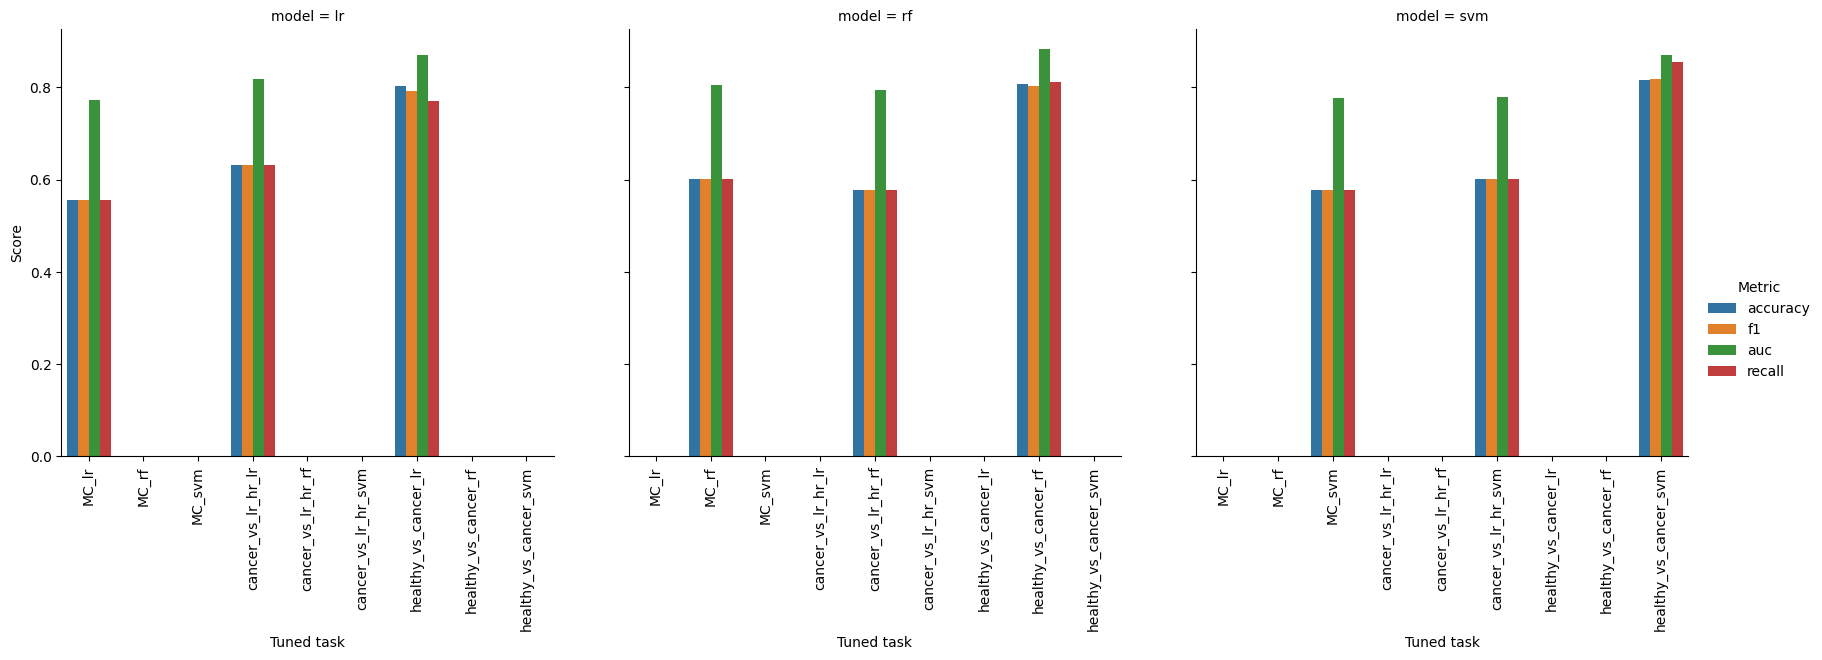

In [13]:
from __future__ import annotations

from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT_DIR = Path("results")  # ggf. anpassen
WANTED_COLS = ["accuracy", "f1", "auc", "recall"]


def discover_metrics_csvs(root: Path) -> Dict[str, Dict[str, Path]]:
    files: Dict[str, Dict[str, Path]] = {}
    for fp in root.rglob("METRICS_*_*.csv"):
        stem = fp.stem.replace("METRICS_", "")
        if "_" not in stem:
            continue
        task, metric = stem.rsplit("_", 1)
        files.setdefault(task, {})[metric] = fp
    return files


def build_table(files_by_task: Dict[str, Dict[str, Path]]) -> pd.DataFrame:
    rows: List[pd.DataFrame] = []

    for task, metrics_map in files_by_task.items():
        for tuning_metric, fp in metrics_map.items():
            df = pd.read_csv(fp)

            cols = [c for c in WANTED_COLS if c in df.columns]
            df = df[cols + (["model"] if "model" in df.columns else [])]

            df["tuned task"] = task
            df["tuning metric"] = tuning_metric

            if "model" in df.columns:
                df = df.set_index(["tuned task", "tuning metric", "model"])
            else:
                df = df.set_index(["tuned task", "tuning metric"])

            rows.append(df)

    if not rows:
        raise ValueError("No metric files found.")

    return pd.concat(rows).sort_index()


# ---- load ----
files = discover_metrics_csvs(ROOT_DIR)
table = build_table(files)

# ---- make long df for seaborn ----
df_long = (
    table.reset_index()
    .melt(
        id_vars=[
            c
            for c in ["tuned task", "tuning metric", "model"]
            if c in table.reset_index().columns
        ],
        value_vars=[c for c in WANTED_COLS if c in table.columns],
        var_name="Metric",
        value_name="Score",
    )
    .dropna(subset=["Score"])
)

# Wenn keine model-Spalte existiert, trotzdem plotten (ohne Facet)
has_model = "model" in df_long.columns

# Optional: Sortierung schöner machen
if "tuned task" in df_long.columns:
    df_long["tuned task"] = pd.Categorical(
        df_long["tuned task"], sorted(df_long["tuned task"].unique()), ordered=True
    )
if "tuning metric" in df_long.columns:
    df_long["tuning metric"] = pd.Categorical(
        df_long["tuning metric"],
        sorted(df_long["tuning metric"].unique()),
        ordered=True,
    )
df_long["Metric"] = pd.Categorical(
    df_long["Metric"],
    [c for c in WANTED_COLS if c in df_long["Metric"].unique()],
    ordered=True,
)

if has_model:
    g = sns.catplot(
        data=df_long,
        kind="bar",
        x="tuned task",
        y="Score",
        hue="Metric",
        col="model",
        row=None,  # "tuning metric",        # <-- wie "Gruppierungsebene" zusätzlich
        errorbar=None,  # <-- keine Whisker
        height=5.2,
        aspect=1.1,
        sharey=True,
    )
    g.set_axis_labels("Tuned task", "Score")
    g.set_xticklabels(rotation=90)

    plt.show()
else:
    plt.figure(figsize=(12, 6))
    ax = sns.barplot(
        data=df_long, x="tuned task", y="Score", hue="Metric", errorbar=None
    )
    ax.set_xlabel("Tuned task")
    ax.set_ylabel("Score")
    plt.tight_layout()
    plt.show()

In [14]:
!./print_tuning_results.py --top 4


Found 63 CSV files

FILE: results/GPU_tuning_BEST_OVERALL_MC_acc.csv
model  fsel        msel                                                 params_json  score_mean  score_std  n_params
   rf Top 8 Skip1 close {"max_depth": 16, "max_features": 0.3, "n_estimators": 300}    0.606861        NaN      2880
  svm Top 8  Opp. close                {"C": 1.0, "gamma": 0.0001, "kernel": "rbf"}    0.599258        NaN      2112
   lr Top 4 Skip1 close                              {"C": 0.001, "max_iter": 1000}    0.593166        0.0      1440

FILE: results/GPU_tuning_BEST_OVERALL_MC_auc.csv
model  fsel        msel                                                params_json  score_mean  score_std  n_params
   rf Top 3 Opp. medium {"max_depth": 8, "max_features": 0.7, "n_estimators": 500}    0.779131        NaN       792
   lr Top 3   Skip1 far                              {"C": 0.01, "max_iter": 2000}    0.767895        NaN       672
  svm Top 3   Skip1 far                            {"C": 0.01, "

In [15]:
from toolbox.util import get_freqs

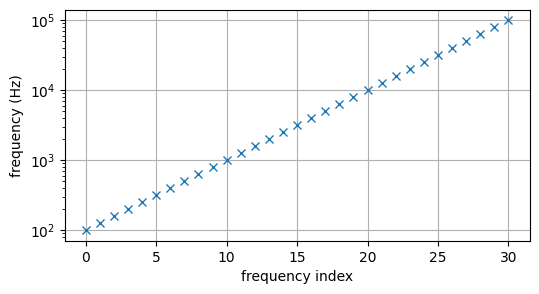

In [16]:
freq_idx, freq_list = get_freqs()

In [17]:
freq_list[9-1]

630.96

___